In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Google Colab
PATH = Path("/content/data")

# Local (comment the line above and uncomment below)
# PATH = Path("diplomacy-deception-detection/data/raw")

for name in ["train.jsonl", "validation.jsonl", "test.jsonl"]:
    print(name, ":", (PATH / name).exists())

train.jsonl : True
validation.jsonl : True
test.jsonl : True


In [3]:
def read_jsonl(path):
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))
    return records

splits = {}
for split in ["train", "validation", "test"]:
    splits[split] = read_jsonl(PATH / f"{split}.jsonl")
    print(f"{split}: {len(splits[split])} conversation records")

train: 189 conversation records
validation: 21 conversation records
test: 42 conversation records


#### Flatten conversations to messages

Keep the original score values and labels. Each output row represents a single message. Check alignment before combining arrays.

In [4]:
fields = [
    "messages", "speakers", "receivers", "sender_labels",
    "game_score", "game_score_delta", "seasons", "years"
]

rows = []
for split, records in splits.items():
    for conversation_index, record in enumerate(records):
        sizes = [len(record[field]) for field in fields]
        if len(set(sizes)) != 1:
            raise ValueError(f"Misaligned arrays: {split}, conversation {conversation_index}")
        for i, message in enumerate(record["messages"]):
            rows.append({
                "split": split,
                "game_id": record["game_id"],
                "conversation_index": conversation_index,
                "message_position": i,
                "message": message,
                "speaker": record["speakers"][i],
                "receiver": record["receivers"][i],
                "sender_label": record["sender_labels"][i],
                "game_score": record["game_score"][i],
                "game_score_delta": record["game_score_delta"][i],
                "season": record["seasons"][i],
                "year": record["years"][i]
            })

df = pd.DataFrame(rows)
print("All messages:", len(df))


All messages: 17289


In [5]:
df.head()

,split,game_id,conversation_index,message_position,message,speaker,receiver,sender_label,game_score,game_score_delta,season,year
0,train,1,0,0,Germany!\n\nJust the person I want to speak wi...,italy,germany,True,3,0,Spring,1901
1,train,1,0,1,"You've whet my appetite, Italy. What's the sug...",germany,italy,True,3,0,Spring,1901
2,train,1,0,2,👍,italy,germany,True,3,0,Spring,1901
3,train,1,0,3,It seems like there are a lot of ways that cou...,germany,italy,True,3,0,Spring,1901
4,train,1,0,4,"Yeah, I can’t say I’ve tried it and it works, ...",italy,germany,True,3,0,Spring,1901


#### training data

In [6]:
train_df = df[df["split"] == "train"].copy()
train_df = train_df[train_df["sender_label"].map(lambda x: type(x) is bool)].copy()
train_df["deceptive"] = train_df["sender_label"].map({True: 0, False: 1})
train_df["class"] = train_df["deceptive"].map({0: "Truthful", 1: "Deceptive"})

display(train_df[[
    "game_id", "speaker", "receiver", "game_score",
    "game_score_delta", "season", "year", "class"
]].head(10))


,game_id,speaker,receiver,game_score,game_score_delta,season,year,class
0,1,italy,germany,3,0,Spring,1901,Truthful
1,1,germany,italy,3,0,Spring,1901,Truthful
2,1,italy,germany,3,0,Spring,1901,Truthful
3,1,germany,italy,3,0,Spring,1901,Truthful
4,1,italy,germany,3,0,Spring,1901,Truthful
5,1,italy,germany,3,0,Spring,1901,Truthful
6,1,italy,germany,3,0,Spring,1901,Truthful
7,1,germany,italy,3,0,Spring,1901,Truthful
8,1,germany,italy,3,0,Spring,1901,Truthful
9,1,italy,germany,3,0,Spring,1901,Truthful


In [7]:

for field in ["game_score", "game_score_delta", "season", "year"]:
    print(f"{field}: types =", train_df[field].map(lambda x: type(x).__name__).value_counts().to_dict())
    print("Example values:", train_df[field].dropna().head(5).tolist())

game_score: types = {'str': 13113, 'int': 19}
Example values: ['3', '3', '3', '3', '3']
game_score_delta: types = {'str': 13122, 'int': 10}
Example values: ['0', '0', '0', '0', '0']
season: types = {'str': 13132}
Example values: ['Spring', 'Spring', 'Spring', 'Spring', 'Spring']
year: types = {'str': 13132}
Example values: ['1901', '1901', '1901', '1901', '1901']


#### Validate score fields and convert numeric values


In [8]:
for field in ["game_score", "game_score_delta", "year"]:
    train_df[field + "_numeric"] = pd.to_numeric(train_df[field], errors="coerce")

summary = pd.DataFrame({
    "non_null_raw": train_df[["game_score", "game_score_delta", "year"]].notna().sum(),
    "numeric_values": pd.Series({
        field: train_df[field + "_numeric"].notna().sum()
        for field in ["game_score", "game_score_delta", "year"]
    })
})
summary["not_numeric_or_missing"] = len(train_df) - summary["numeric_values"]
summary



,non_null_raw,numeric_values,not_numeric_or_missing
game_score,13132,13132,0
game_score_delta,13132,13132,0
year,13132,13132,0


In [9]:
train_df[[
    "game_score_numeric", "game_score_delta_numeric", "year_numeric"
]].describe()

,game_score_numeric,game_score_delta_numeric,year_numeric
count,13132.000000,13132.000000,13132.000000
mean,5.326226,0.071429,1903.535029
std,2.049506,2.150761,2.373907
min,0.000000,-14.000000,1901.000000
25%,4.000000,-1.000000,1902.000000
50%,5.000000,0.000000,1903.000000
75%,6.000000,1.000000,1905.000000
max,17.000000,14.000000,1910.000000


#### deception rate

In [10]:
total = len(train_df)
lies = int(train_df["deceptive"].sum())
print("Training messages:", total)
print("Deceptive messages:", lies)
print("Deception rate (%):", round(100 * lies / total, 2) if total else None)

Training messages: 13132
Deceptive messages: 591
Deception rate (%): 4.5


#### Compare recorded game scores by sender label


In [11]:
display(train_df.groupby("class")["game_score_numeric"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2))


,count,mean,median,min,max
class,,,,,
Deceptive,591,6.05,5.0,0,13
Truthful,12541,5.29,5.0,0,17


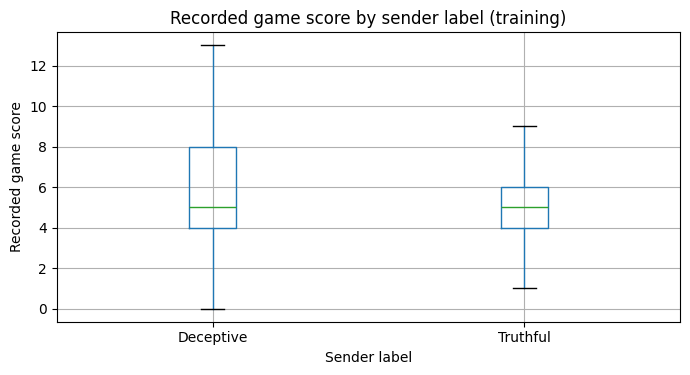

In [12]:

plot_df = train_df.dropna(subset=["game_score_numeric"])
if not plot_df.empty:
    plot_df.boxplot(column="game_score_numeric", by="class", figsize=(7, 4), showfliers=False)
    plt.title("Recorded game score by sender label (training)")
    plt.suptitle("")
    plt.xlabel("Sender label")
    plt.ylabel("Recorded game score")
    plt.tight_layout()
    plt.show()

#### Compare game-score deltas by sender label

A delta may reflect a changing game state, but its precise meaning depends on the original dataset specification.

In [13]:
display(train_df.groupby("class")["game_score_delta_numeric"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2))


,count,mean,median,min,max
class,,,,,
Deceptive,591,1.04,0.0,-10,10
Truthful,12541,0.03,0.0,-14,14


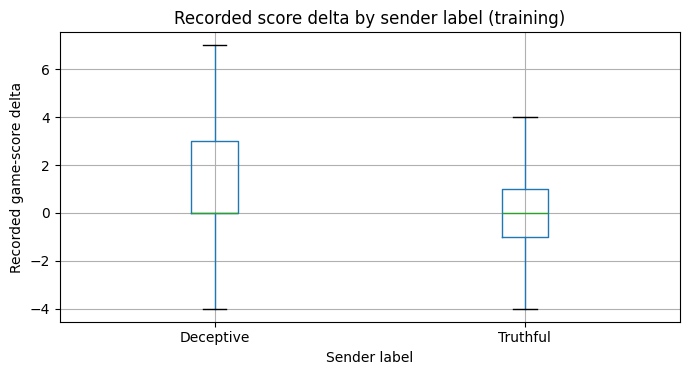

In [14]:

plot_df = train_df.dropna(subset=["game_score_delta_numeric"])
if not plot_df.empty:
    plot_df.boxplot(column="game_score_delta_numeric", by="class", figsize=(7, 4), showfliers=False)
    plt.title("Recorded score delta by sender label (training)")
    plt.suptitle("")
    plt.xlabel("Sender label")
    plt.ylabel("Recorded game-score delta")
    plt.tight_layout()
    plt.show()

#### Deception rates across score ranges


,messages,deceptive_messages,deception_rate,deception_rate_percent
score_group,,,,
"(-0.001, 4.0]",4733,211,0.044581,4.46
"(4.0, 5.0]",3710,102,0.027493,2.75
"(5.0, 6.0]",1555,57,0.036656,3.67
"(6.0, 17.0]",3134,221,0.070517,7.05


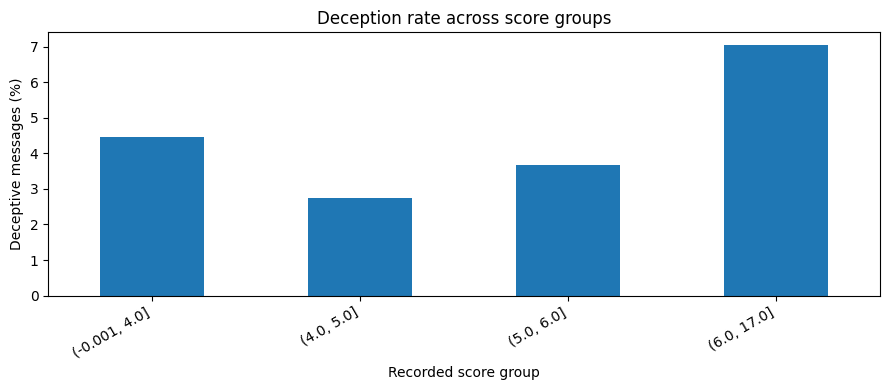

In [15]:
score_df = train_df.dropna(subset=["game_score_numeric"]).copy()
if score_df["game_score_numeric"].nunique() >= 2:
    score_df["score_group"] = pd.qcut(
        score_df["game_score_numeric"], q=4, duplicates="drop"
    )
    score_summary = score_df.groupby("score_group", observed=True).agg(
        messages=("deceptive", "size"),
        deceptive_messages=("deceptive", "sum"),
        deception_rate=("deceptive", "mean")
    )
    score_summary["deception_rate_percent"] = (100 * score_summary["deception_rate"]).round(2)
    display(score_summary)

    score_summary["deception_rate_percent"].plot.bar(figsize=(9, 4))
    plt.ylabel("Deceptive messages (%)")
    plt.xlabel("Recorded score group")
    plt.title("Deception rate across score groups")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough distinct numeric game scores to create groups.")

#### Deception rates by score-delta direction


,messages,deceptive_messages,deception_rate_percent
delta_group,,,
Negative,4183,114,2.73
Positive,4481,287,6.40
Zero,4468,190,4.25


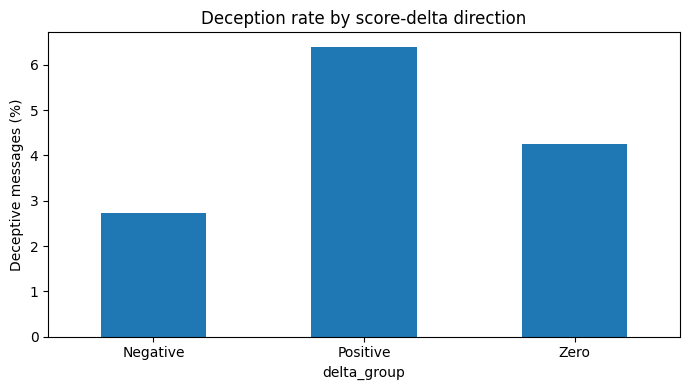

In [16]:
delta_df = train_df.dropna(subset=["game_score_delta_numeric"]).copy()

def delta_category(value):
    if value < 0:
        return "Negative"
    if value > 0:
        return "Positive"
    return "Zero"

delta_df["delta_group"] = delta_df["game_score_delta_numeric"].apply(delta_category)
delta_summary = delta_df.groupby("delta_group").agg(
    messages=("deceptive", "size"),
    deceptive_messages=("deceptive", "sum"),
    deception_rate_percent=("deceptive", lambda x: round(100 * x.mean(), 2))
)
display(delta_summary)

if not delta_summary.empty:
    delta_summary["deception_rate_percent"].plot.bar(figsize=(7, 4))
    plt.ylabel("Deceptive messages (%)")
    plt.title("Deception rate by score-delta direction")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

#### Deception by game phase

Inspect `season` and `year`

,messages,deceptive_messages,deception_rate_percent
season,,,
Fall,5668,236,4.16
Spring,5754,297,5.16
Winter,1710,58,3.39


,messages,deception_rate_percent
year,,
1901,3131,5.59
1902,2933,3.14
1903,1548,4.13
1904,1226,3.10
1905,1430,1.61
1906,858,5.83
1907,1133,10.41
1908,397,5.04
1909,288,3.47


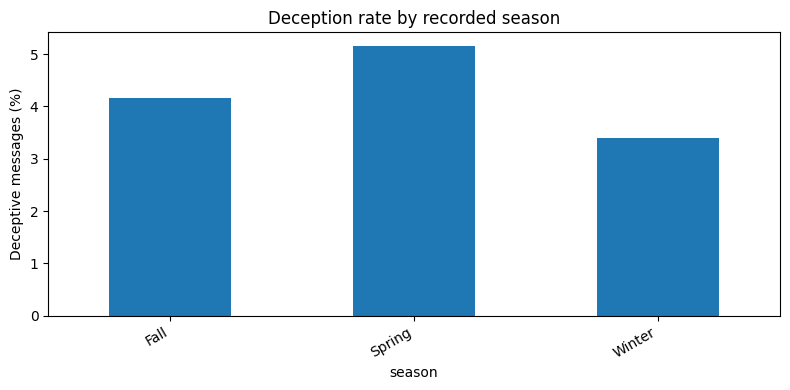

In [17]:
season_summary = train_df.groupby("season", dropna=False).agg(
    messages=("deceptive", "size"),
    deceptive_messages=("deceptive", "sum"),
    deception_rate_percent=("deceptive", lambda x: round(100 * x.mean(), 2))
)
display(season_summary)

year_summary = train_df.groupby("year", dropna=False).agg(
    messages=("deceptive", "size"),
    deception_rate_percent=("deceptive", lambda x: round(100 * x.mean(), 2))
)
display(year_summary.sort_index())

if not season_summary.empty:
    season_summary["deception_rate_percent"].plot.bar(figsize=(8, 4))
    plt.ylabel("Deceptive messages (%)")
    plt.title("Deception rate by recorded season")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

#### Compare across games


In [19]:
game_summary = train_df.groupby("game_id").agg(
    messages=("deceptive", "size"),
    deceptive_messages=("deceptive", "sum"),
    deception_rate_percent=("deceptive", lambda x: round(100 * x.mean(), 2)),
    mean_recorded_score=("game_score_numeric", "mean"),
    mean_recorded_delta=("game_score_delta_numeric", "mean")
)
game_summary.round(2)


,messages,deceptive_messages,deception_rate_percent,mean_recorded_score,mean_recorded_delta
game_id,,,,,
1,2618,219,8.37,5.67,0.14
2,3302,78,2.36,5.69,0.13
3,1914,45,2.35,5.20,0.06
5,427,41,9.60,5.03,-0.05
6,521,50,9.60,5.15,0.15
7,1003,45,4.49,4.19,0.05
8,905,27,2.98,5.72,0.04
9,1611,56,3.48,4.95,-0.13
10,831,30,3.61,5.03,0.11


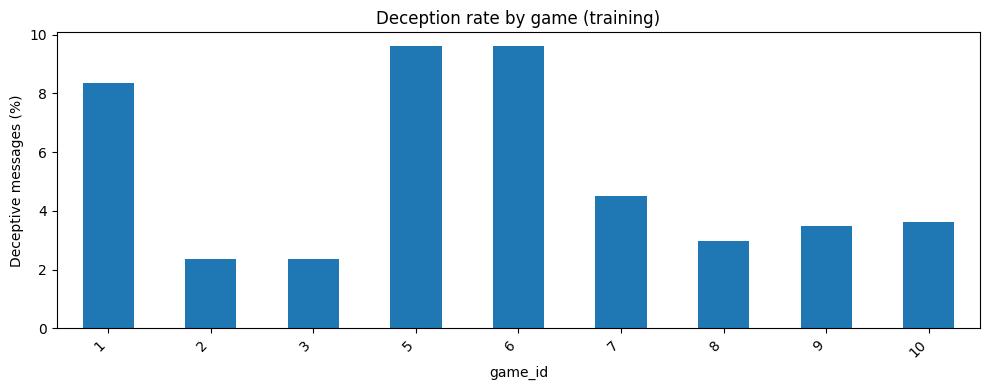

In [20]:

game_summary["deception_rate_percent"].plot.bar(figsize=(10, 4))
plt.ylabel("Deceptive messages (%)")
plt.title("Deception rate by game (training)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Compare speaker and receiver activity


In [21]:
speaker_summary = train_df.groupby("speaker").agg(
    sent_messages=("deceptive", "size"),
    deceptive_messages=("deceptive", "sum"),
    deception_rate_percent=("deceptive", lambda x: round(100 * x.mean(), 2))
)
display(speaker_summary.sort_values("sent_messages", ascending=False))


,sent_messages,deceptive_messages,deception_rate_percent
speaker,,,
germany,2687,56,2.08
italy,2493,208,8.34
england,2304,79,3.43
austria,1827,59,3.23
russia,1317,51,3.87
france,1279,91,7.11
turkey,1225,47,3.84


In [22]:

receiver_summary = train_df.groupby("receiver").agg(
    received_messages=("deceptive", "size"),
    deceptive_messages_received=("deceptive", "sum")
)
display(receiver_summary.sort_values("received_messages", ascending=False))

,received_messages,deceptive_messages_received
receiver,,
germany,2851,133
italy,2376,60
england,2269,114
austria,1758,82
russia,1519,67
france,1220,61
turkey,1139,74


#### examples at different score levels

In [23]:
examples = train_df.dropna(subset=["game_score_numeric"]).sort_values(
    "game_score_numeric"
)
if not examples.empty:
    selected = pd.concat([examples.head(3), examples.tail(3)])
    display(selected[[
        "game_id", "speaker", "receiver", "class",
        "game_score_numeric", "game_score_delta_numeric",
        "season", "year", "message"
    ]])
else:
    print("No numeric game scores available for examples.")

,game_id,speaker,receiver,class,game_score_numeric,game_score_delta_numeric,season,year,message
2240,1,austria,russia,Truthful,0,-5,Winter,1910,The effort was appreciated.
2333,1,france,austria,Truthful,0,-3,Winter,1907,My gift to you is willingly suiciding so that ...
2171,1,france,germany,Truthful,0,-7,Winter,1907,GG! Good luck!
8781,6,turkey,france,Truthful,17,10,Spring,1909,Maybe?
8445,6,turkey,germany,Truthful,17,14,Fall,1909,How you doin'?
8448,6,turkey,germany,Truthful,17,14,Fall,1910,"Hey, I'm an empathetic guy :)\nSeriously just ..."
